**Aim:** anlysis of scRNA-seq data

**Tools**: 
1. Preprocessing: [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
2. Integrating and Comparing Samples

# 1. Preprocessing

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.7.2 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://www.techcoil.com/blog/how-to-save-and-load-objects-to-and-from-file-in-python-via-facilities-from-the-pickle-module/

def save_obj(obj, name ):
    with open(name, 'wb') as f:
        pickle.dump(obj, f, pickle.HIGHEST_PROTOCOL)

def load_obj(name ):
    with open(name, 'rb') as f:
        return pickle.load(f)

### Load `cellranger` results and label samples

<!-- https://www.kallistobus.tools/tutorials/kb_aggregate/python/kb_aggregating_count_matrices.html -->



In [7]:
%%time 
data = {}
for file in sorted(glob('counts/*/outs/filtered_feature_bc_matrix.h5')):
    sample = file.split('/')[1].replace('-','')
    print (sample, file)
    
    adata = sc.read_10x_h5(file)#, gex_only=False)
    
    data[sample] = adata
    del adata
    print ('_'*50)


MDMAMale counts/MDMA-Male/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
MDMA_acute_female_011221 counts/MDMA_acute_female_011221/outs/filtered_feature_bc_matrix.h5
__________________________________________________
MDMA_acute_female_100121 counts/MDMA_acute_female_100121/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
MDMA_acute_female_180921 counts/MDMA_acute_female_180921/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


... (15 outputs left out)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
Saline_202110 counts/Saline_202110/outs/filtered_feature_bc_matrix.h5


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


__________________________________________________
CPU times: user 4.69 s, sys: 1.27 s, total: 5.96 s
Wall time: 6.55 s


In [25]:
!mkdir -pv preprocessing

mkdir: created directory ‘preprocessing’


In [8]:
name = 'preprocessing/adatas-raw.pkl'

save_obj(data, name)

In [9]:
ls -s --block-size=M preprocessing/adatas-raw.pkl

484M preprocessing/adatas-raw.pkl


___


## Data cleaning

Filtering cells with high mitochondrial gene counts
- https://www.biostars.org/p/347428/
- https://github.com/theislab/scanpy/issues/639

In [76]:
name = 'preprocessing/adatas-raw.pkl'
data = load_obj(name)

In [11]:
new_keys = [
    'MDMA_male_1',
    'MDMA_acute_female_1',
    'MDMA_acute_female_2',
    'MDMA_acute_female_3',
    'MDMA_acute_male_1',
    'MDMA_acute_male_2',
    'MDMA_acute_male_3',

    'MDMA_male_2',
    'MDMA_male_3',
    
    'Meth_male_1',
    'Meth_male_2',
    'Meth_male_3',
    
    'Saline_male_1',
    'Saline_male_2',
    'Saline_male_3'
]

In [12]:
def rename(d, new_keys):
    """
    https://stackoverflow.com/questions/16475384/rename-a-dictionary-key
    """
    new_dict = {}
    for key, new_key in zip(d.keys(), new_keys):
        new_dict[new_key] = d[key]
        print(f'{new_key} <- {key}')
        
    return new_dict

In [13]:
data = rename(data,new_keys)

MDMA_male_1 <- MDMAMale
MDMA_acute_female_1 <- MDMA_acute_female_011221
MDMA_acute_female_2 <- MDMA_acute_female_100121
MDMA_acute_female_3 <- MDMA_acute_female_180921
MDMA_acute_male_1 <- MDMA_acute_male
MDMA_acute_male_2 <- MDMA_acute_male_021221_1
MDMA_acute_male_3 <- MDMA_acute_male_021221_2
MDMA_male_2 <- MDMA_male_093021
MDMA_male_3 <- MDMA_male_100121
Meth_male_1 <- Meth
Meth_male_2 <- Meth_093021
Meth_male_3 <- Meth_100121
Saline_male_1 <- SalineMale
Saline_male_2 <- Saline_093021
Saline_male_3 <- Saline_202110


In [14]:
# def preprocessing(adata):
#     adata.var_names_make_unique()
#     # Basic filtering:
#     adata.layers["counts"] = adata.X.copy()
# #     sc.pp.filter_genes(adata, min_counts=1)
#     return adata

#     sc.pp.filter_genes(adata, min_cells=10)
#     sc.pp.filter_cells(adata, min_genes=150)
#     # Identify highly-variable genes.
#     sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     adata.raw = adata
#     # Actually do the filtering
#     adata = adata[:, adata.var.highly_variable]

def filter_mt(adata,n=10):
    
    adata.layers["counts"] = adata.X.copy()
    
    # mitochondrial genes
    adata.var['mt'] = adata.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)
    # filter based on MT counts % 
    keep = adata.obs.pct_counts_mt < n
    t0 = adata.shape[0]
    adata = adata[adata.obs.pct_counts_mt < n, :]
    t1 = adata.shape[0]
    print (f'`filter_mt` -> from #{t0} cells filter #{t0-t1}!')
    return adata

def remove_doublet(adata):
    # remove doublet
    sce.pp.scrublet(adata)
    adata  = adata[adata.obs.doublet_score < adata.uns['scrublet']['threshold']]
    return adata

#### Plot mitochondrial QC plot

In [15]:
mkdir -pv figures

In [16]:
# %%time
# for sample in data:
#     print (sample)
#     tmpdata = data[sample].copy()
#     tmpdata.var_names_make_unique()
#     # mitochondrial genes
#     tmpdata.var['mt'] = tmpdata.var_names.str.startswith('mt-')  
#     # annotate the group of mitochondrial genes as 'mt'
#     sc.pp.calculate_qc_metrics(
#         tmpdata, qc_vars=['mt'], percent_top=None, 
#         log1p=False, inplace=True
#     )
#     # The PDF document
#     pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
#     for col in [
#         'n_genes_by_counts','total_counts',
#         'pct_counts_mt'
#     ]:
#         # Create a figure instance (ie. a new page)
#         fig = plot.figure(figsize=(12, 6), dpi=300)
#         # Plot whatever you wish to plot
#         print ('\033[1m' + col)
#         ax = plt.subplot()
#         sc.pl.violin(
#             tmpdata, col, jitter=0.4, #groupby='batch', 
#             multi_panel=True, ax=ax
#         )
#         # Done with the page
#         pdf_pages.savefig(fig)
#     # Write the PDF document to the disk
#     pdf_pages.close()
#     del tmpdata

In [31]:
EXPs = []
OBSs = []
for sample in data:
    
    print (sample)
    exp = data[sample].copy()
    exp.obs['batch'] = sample
    EXPs.append(exp.to_df())
    OBSs.append(exp.obs)
    
    # del exp 

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_male_1
MDMA_acute_female_1
MDMA_acute_female_2
MDMA_acute_female_3
MDMA_acute_male_1


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_male_2


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_male_3
MDMA_male_2


... (2 outputs left out)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Meth_male_2
Meth_male_3
Saline_male_1
Saline_male_2


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Saline_male_3


In [32]:
adata = ad.AnnData(
    X=pd.concat(EXPs),obs=pd.concat(OBSs)
)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [33]:
adata

AnnData object with n_obs × n_vars = 24816 × 32285
    obs: 'batch'

In [34]:
adata.obs['cond'] = adata.obs['batch'].str[:-2]

In [35]:
adata.var['mt'] = adata.var_names.str.startswith('mt-')

In [36]:
for c in set(adata.obs['cond']): print(c)

MDMA_acute_female
Saline_male
MDMA_acute_male
MDMA_male
Meth_male


### plot

In [37]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, 
    log1p=False, inplace=True
)

In [38]:
cond = 'all'

In [40]:
adata.var_names_make_unique()

n_genes_by_counts


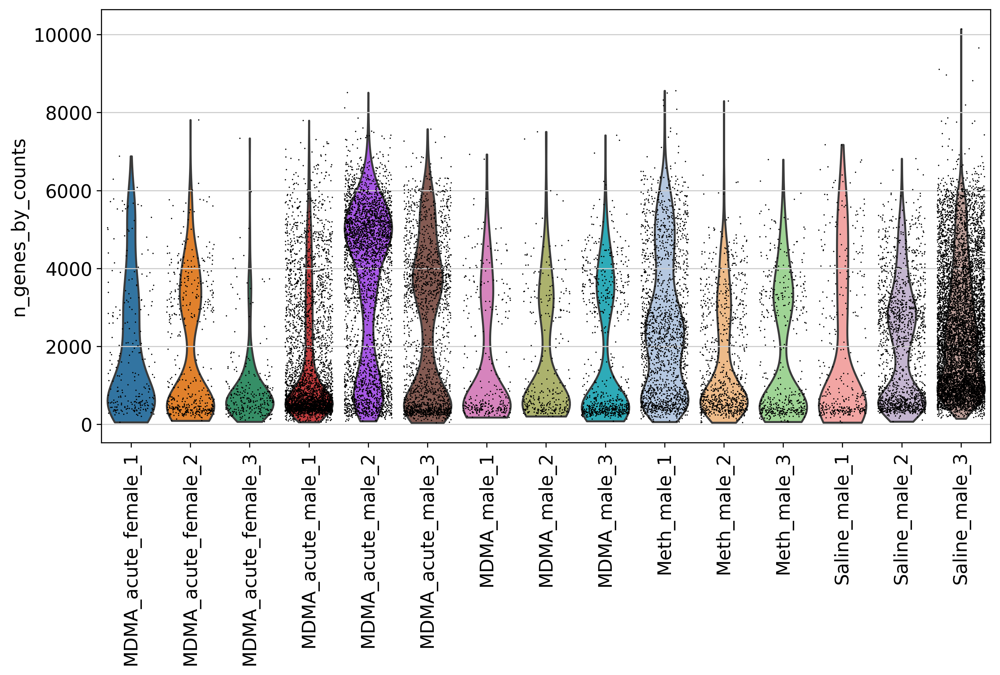

total_counts


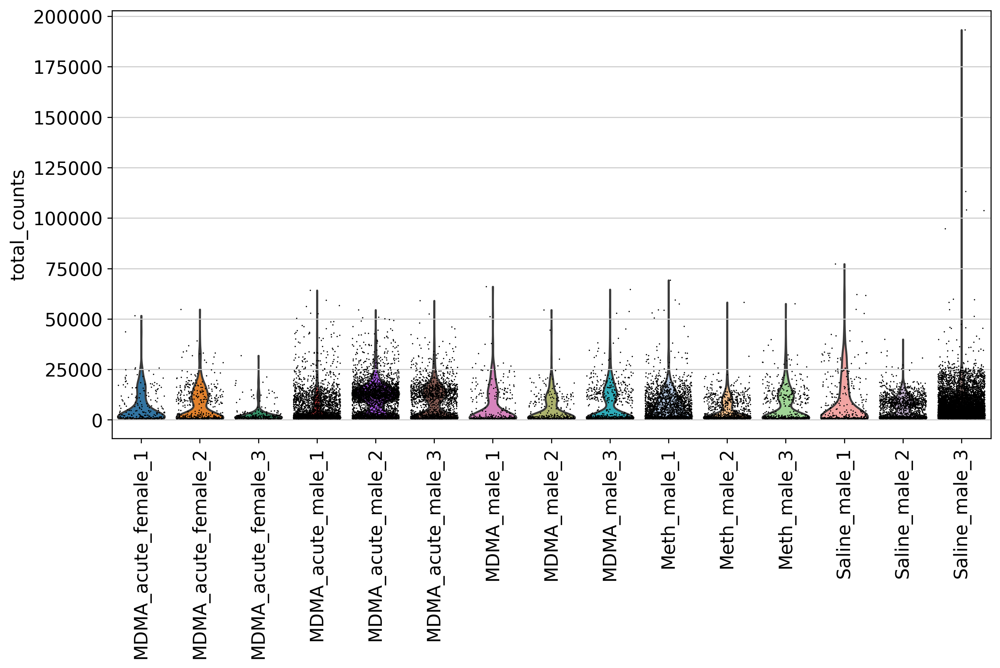

pct_counts_mt


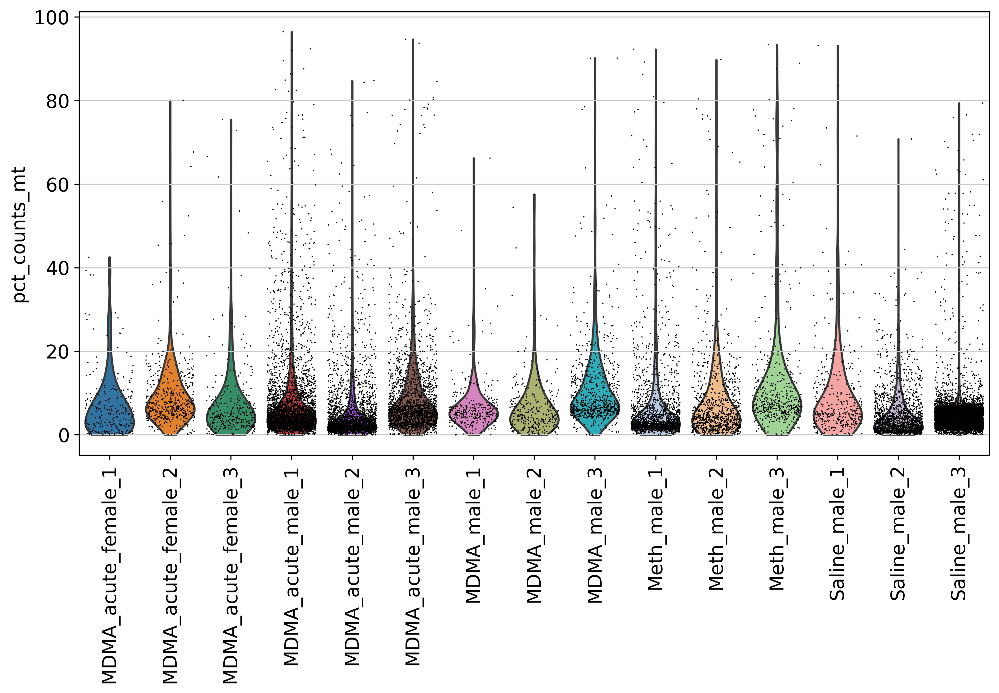

In [41]:
pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
for col in [
    'n_genes_by_counts','total_counts',
    'pct_counts_mt'
]:
    # Create a figure instance (ie. a new page)
    fig = plot.figure(figsize=(12, 6), dpi=300)
    # Plot whatever you wish to plot
    print ('\033[1m' + col)
    ax = plt.subplot()
    sc.pl.violin(
        adata, col, jitter=0.4, groupby='batch', 
        multi_panel=True, ax=ax,rotation=90
    )
    # Done with the page
    pdf_pages.savefig(fig,bbox_inches='tight')
# Write the PDF document to the disk
pdf_pages.close()

### Actual filtering 

In [42]:
adata_flt_mt = filter_mt(adata,n=20)

`filter_mt` -> from #24816 cells filter #1194!


In [43]:
adata_flt_dd = remove_doublet(adata_flt_mt)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:138: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


Automatically set threshold at doublet score = 0.50
Detected doublet rate = 0.4%
Estimated detectable doublet fraction = 39.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.9%


Trying to set attribute `.obs` of view, copying.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [44]:
for col in adata_flt_dd.var.columns: 
    del adata_flt_dd.var[col]

for col in adata_flt_dd.obs.columns: 
    if col == 'batch' or col == 'cond':
        pass
    else:
        del adata_flt_dd.obs[col]
del adata_flt_dd.uns

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [45]:
results_file = 'preprocessing/adatas-merge-reps-clean.h5ad.gz'
adata_flt_dd.write(results_file,compression='gzip')

In [46]:
!ls -s --block-size=M preprocessing/adatas-merge-reps-clean.h5ad.gz

384M preprocessing/adatas-merge-reps-clean.h5ad.gz


## Clustering 

In [47]:
def clustering(adata,lognorm=False,rep=None, n_neighbor=30,res=None):
    if lognorm: 
        sc.pp.log1p(adata)
    sc.pp.pca(adata)
    sc.pp.neighbors(adata, use_rep=rep, n_neighbors=n_neighbor)   # why can't we just work with the default neighbors?
    sc.tl.umap(adata)
    sc.tl.leiden(adata,resolution=res)


In [48]:
adata2 = adata_flt_dd.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [49]:
sc.pp.normalize_total(adata2, target_sum=1e4)

In [50]:
sc.pp.log1p(adata)

In [51]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

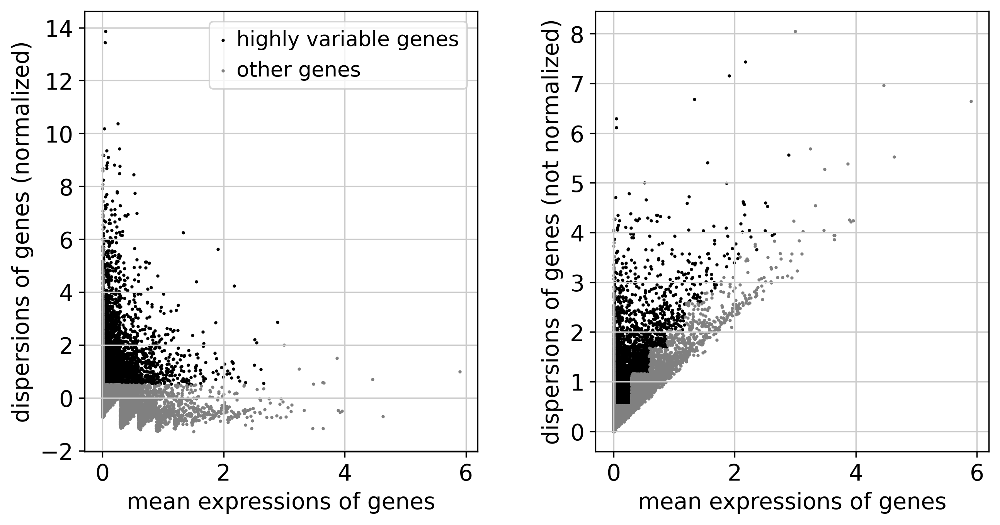

In [52]:
sc.pl.highly_variable_genes(adata)

In [53]:
clustering(adata2)

In [54]:
sc.pl.umap(adata2, color='cond',save='_cond.pdf')

In [55]:
sc.pl.umap(adata2, color='batch',save='_batch.pdf')

In [56]:
sc.pl.umap(adata2, color='leiden',legend_loc='on data', title='', frameon=False,save='_leiden.pdf',)

In [ ]:
sc.tl.rank_genes_groups(adata2, 'leiden', method='logreg')

In [ ]:
rank_genes_df = pd.DataFrame(adata2.uns['rank_genes_groups']['names'])

In [ ]:
rank_genes_df.to_excel("celltyping/rank_genes_df.xlsx",
             sheet_name='leiden clusters')

In [ ]:
adata2.var_names_make_unique()

In [ ]:
sc.pl.violin(
    adata2,
    list({gene for l in rank_genes_df.head(1).values.tolist() for gene in l}), 
    groupby='cond',save='_rank_genes_groups.png',rotation=90
)

In [ ]:
sc.pl.rank_genes_groups(adata2, n_genes=20, sharey=False,save='.pdf')

In [ ]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='leiden',
    # title='mRNA Clusters',
    save='leiden.pdf',
    dendrogram=True
)

In [ ]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='cond',
    # title='mRNA Clusters',
    save='cond.pdf',
    dendrogram=True
)

### Meth_male

In [ ]:
Meth_male = adata2[adata2.obs.cond == 'Meth_male']

### MDMA_male

In [ ]:
MDMA_male = adata2[adata2.obs.cond == 'MDMA_male']

### Saline_male

In [ ]:
Saline_male = adata2[adata2.obs.cond == 'Saline_male']

### MDMA_acute_male

In [ ]:
MDMA_acute_male = adata2[adata2.obs.cond == 'MDMA_acute_male']

### MDMA_acute_female

In [ ]:
MDMA_acute_female = adata2[adata2.obs.cond == 'MDMA_acute_female']

## 3. 
https://docs.scvi-tools.org/

In [ ]:
def prep_totalVI(adata):
    ## Prepare and run model
    scvi.data.setup_anndata(
        adata, 
        batch_key="batch", 
        protein_expression_obsm_key="protein_expression"
    )

def make_vae(adata):
    vae = scvi.model.TOTALVI(adata, latent_distribution="normal")
    vae.train()

    return vae

In [ ]:
def analyze_outputs(adata0,vae,batches):
    '''Analyze outputs
    We use Scanpy for clustering and visualization after running totalVI. 
    It's also possible to save totalVI outputs for an R-based workflow. 
    First, we store the totalVI outputs in the appropriate slots in AnnData.
    
    Parameters:
    adata0 (AnnData): input `adata` object
    vae (AnnData): input `adata` object
  
    Returns:
    AnnData: output `adata` object with denoised rna and protein counts 
    '''
    
    adata = adata0.copy()
    
    adata.obsm["X_totalVI"] = vae.get_latent_representation()

    rna, protein = vae.get_normalized_expression(
        n_samples=25, 
        return_mean=True, 
        transform_batch=batches
    )

    adata.layers["denoised_rna"], adata.obsm["denoised_protein"] = rna, protein
    
    adata.obsm["protein_foreground_prob"] = vae.get_protein_foreground_probability(
        n_samples=25, 
        return_mean=True, 
        transform_batch=batches
    )
    
    return adata

### Imports and data loading

In [ ]:
name = 'preprocessing/adatas-merge-reps-clean.pkl'
data = load_obj(name)

In [ ]:
for cond in data:
    print (cond)
    
    prep_totalVI(data[cond])
    
    print ('_'*70)    

In [ ]:
all (
    data['B6'].obs.index == data['B6'].obsm['protein_expression'].index
)

### Run `totalVI`

### Plot training epochs ...

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=1,figsize=(5,10),dpi=300)
x = 141

for i,cond in enumerate(VAEs):
    vae = VAEs[cond]
    axes[i].plot(vae.history["elbo_train"], label="train")
    axes[i].plot(vae.history["elbo_validation"], label="validation")
    axes[i].set_title(f"{cond}")
    # axes[i].set_ylim(9000, 15000)
    axes[i].legend()

fig.suptitle('Negative ELBO over training epochs')
fig.tight_layout()
fig.savefig('figures/totalVI_training.pdf')

In [ ]:
save_obj(data_denoised, 'preprocessing/adatas-totalVI-denoised.pkl')

In [ ]:
ls -s --block-size=G preprocessing/adatas-totalVI-denoised.pkl

___

# 3. Integrating and Comparing Samples
- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.harmony_integrate.html

> `harmony_integrate` function uses the python port of Harmony, [harmonypy](https://github.com/slowkow/harmonypy), to integrate single-cell data stored in an AnnData object. As Harmony works by **adjusting the principal components**, this function should be **run after performing PCA but before computing the neighbor graph**.

- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.mnn_correct.html#scanpy.external.pp.mnn_correct


- https://github.com/JinmiaoChenLab/Batch-effect-removal-benchmarking

> Based on our results, Harmony, LIGER, and Seurat 3 are the recommended methods for batch integration. Due to its significantly shorter runtime, **Harmony** is recommended as the first method to try, with the other methods as viable alternatives.

<!-- Aidan's notes 
> The 4 strategies I will try are: 
> 1. No integration (just mergin all datasets together). This will give me a sense of the batch effect between samples
> 2. Seurat standard integration (using the anchro identification method)
> 3. Seurat scTransform (adjusts counts based on umi per cell)
> 4. Harmony

Try [harmonypy](https://anaconda.org/bioconda/harmonypy)

These are the critical R packages I used to write [this note](https://slowkow.com/notes/harmony-animation/):
- [MUDAN](https://github.com/jefworks/MUDAN) by Jean Fan
- [Harmony](https://github.com/immunogenomics/harmony) and [presto](https://github.com/immunogenomics/presto) by Ilya Korsunsky
- [gganimate](https://gganimate.com/) by Thomas Lin Pedersen -->

In [ ]:
name = 'preprocessing/adatas-totalVI-denoised.pkl'
data_denoised = load_obj(name)

In [ ]:
# def clustering(adata,lognorm=False,rep=None, n_neighbor=30,res=None):
#     if lognorm: 
#         sc.pp.log1p(adata)
#     sc.pp.pca(adata)
#     sc.pp.neighbors(adata, use_rep=rep, n_neighbors=n_neighbor)   # why can't we just work with the default neighbors?
#     sc.tl.umap(adata)
#     sc.tl.leiden(adata,resolution=res)


# def join_graphs_max(g1: "sparse.spmatrix", g2: "sparse.spmatrix"):
#     """Take the maximum edge value from each graph."""
#     out = g1.copy()
#     mask = g1 < g2
#     out[mask] = g2[mask]
#     return out
#     adata.obsp["connectivities"] = join_graphs_max(adata.obsp["rna_connectivities"], adata.obsp["protein_connectivities"])
#     sc.pp.neighbors(adata, n_neighbors=30)   # why can't we just work with the default neighbors?
#     sc.tl.leiden(adata, key_added="joint_leiden")
#     sc.tl.umap(adata)


# def annotate_rna_protein(adata):
#     '''Annotate data based on mRNA expression and surface protein abundance 
#     '''
#     protein = adata[:, adata.var["feature_types"] == "Antibody Capture"].copy()
    
#     clustering(protein,lognorm=True)
    
#     protein.var.set_index('gene_ids',inplace=True)    
#     adata.obs = pd.concat([adata.obs,protein.to_df()],axis=1) 
    
#     print ('protein clustering is done!')
    
#     rna = adata[:, adata.var["feature_types"] == "Gene Expression"].copy()
#     clustering(rna,lognorm=True)

#     print ('RNA clustering is done!')

#     odata = rna.copy()
    
#     odata.obsm["protein_umap"] = protein.obsm["X_umap"]
#     odata.obs["protein_leiden"] = protein.obs["leiden"]
#     odata.obsp["protein_connectivities"] = protein.obsp["connectivities"].copy()

#     odata.obsm["rna_umap"] = rna.obsm["X_umap"]
#     del odata.obs["leiden"]
#     odata.obs["rna_leiden"] = rna.obs["leiden"]
#     odata.obsp["rna_connectivities"] = rna.obsp["connectivities"].copy()
    
#     return odata

In [ ]:
def umap_totalVI(adata,ax=None):
    """Now we can compute clusters and visualize the latent space.
    """
    sc.pp.neighbors(adata, use_rep="X_totalVI")
    sc.tl.umap(adata, min_dist=0.4)
    sc.tl.leiden(adata, key_added="leiden_totalVI")

    sc.pl.umap(
        adata, 
        color=[
#             "leiden_totalVI", 
            "batch"
        ], 
        frameon=False,ncols=1,ax=ax
    )

In [ ]:
def make_pro_adata(adata):
    """Visualize denoised protein values
    To visualize protein values on the umap, we make a temporary protein adata object.
    We have to copy over the umap from the original adata object.
    """
    pro_adata = sc.AnnData(adata.obsm["protein_expression"].copy(), obs=adata.obs)
    sc.pp.log1p(pro_adata)
    # Keep log normalized data in raw
    pro_adata.raw = pro_adata
    pro_adata.X = adata.obsm["denoised_protein"]

    pro_adata.obsm["X_umap"] = adata.obsm["X_umap"]
    pro_adata.obsm["X_totalVI"] = adata.obsm["X_totalVI"]

    # from .obsm -> .obs
    names = adata.obsm["protein_foreground_prob"].columns
    for p in names:
        pro_adata.obs["{}_fore_prob".format(p)] = adata.obsm["protein_foreground_prob"].loc[:, p]
    return pro_adata

def umap_pro_totalVI(adata,sample=''):
    ### Visualize denoised protein values
    # plot umap
    fig1 = sc.pl.umap(
        pro_adata, 
        color=pro_adata.var_names,
        ncols=3, 
        vmax="p99",
        use_raw=False,
        frameon=False,
        return_fig=True,
        wspace=0.1
    )
    fig1.suptitle(f'{sample}\ndenoised protein values\n{str(adata.shape[0])} cells')
    
    ### Visualize probability of foreground
    fig2 = sc.pl.umap(
        pro_adata,
        color=["{}_fore_prob".format(p) for p in pro_adata.var_names],
        ncols=3,
        color_map="cividis",
        frameon=False,
        wspace=0.1,
        return_fig=True
    )
    fig2.suptitle('probability of foreground')
    return fig1,fig2

> Here we visualize the probability of foreground for each protein and cell (projected on UMAP).
Some proteins are easier to disentangle than others. Some proteins end up being "all background".
For example, CD15 does not appear to be captured well, when looking at the denoised values above we see little localization in the monocytes.

> __Note__: 
>> While the foreground probability could theoretically be used to identify cell populations, we recommend using the denoised protein expression, which accounts for the foreground/background probability, but preserves the dynamic range of the protein measurements. Consequently, the denoised values are on the same scale as the raw data and it may be desirable to take a transformation like log or square root.
> By viewing the foreground probability, we can get a feel for the types of cells in our dataset. For example, it's very easy to see a population of monocytes based on the CD14 foregroud probability.


In [78]:
%%time 
fig, axes = plt.subplots(nrows=3, ncols=1,figsize=(5,10),dpi=300)
i = 0
for cond, adata in data_denoised.items():
    umap_totalVI(adata,axes[i])
    axes[i].set_title(cond)
    i+=1

fig.suptitle('totalVI denoised RNA data')
fig.tight_layout()
fig.savefig('figures/totalVI_RNA_umap.pdf')

CPU times: user 2min 44s, sys: 7.67 s, total: 2min 52s
Wall time: 52.6 s


In [74]:
%%time 
for cond, adata in data_denoised.items():
    print ('\033[1m' + cond)
    pdf_pages = PdfPages(f'figures/totalVI_Protein_umap_{cond}.pdf')
    # The PDF document
    # Create a figure instance (ie. a new page)
    fig1 = plot.figure(dpi=300)
    fig2 = plot.figure(dpi=300)
    # Plot whatever you wish to plot
    pro_adata=make_pro_adata(adata)
    fig1,fig2 = umap_pro_totalVI(pro_adata,cond)
    # Done with the page
    fig1.set_size_inches(18.5, 10.5)
    pdf_pages.savefig(fig1)
    plt.close(fig1)    
    fig2.set_size_inches(18.5, 10.5)
    pdf_pages.savefig(fig2)
    plt.close(fig2)
    # Write the PDF document to the disk
    pdf_pages.close()

B6
Rag
NSG
CPU times: user 6.95 s, sys: 856 ms, total: 7.81 s
Wall time: 7.76 s


___

Save each sample into a `h5ad` file.

In [ ]:
# data = {}

for cond in data_denoised:
    print (cond)

    # adata = ad.AnnData(
    #     # denoised rna counts
    #     X=pd.DataFrame(
    #         data   = data_denoised[cond].layers['denoised_rna'],
    #         index  = data_denoised[cond].obs.index,
    #         columns= data_denoised[cond].var.index
    #     ),
    #     # batch + denoised protein counts
    #     obs=pd.concat([
    #         data_denoised[cond].obs['batch'],
    #         data_denoised[cond].obsm['denoised_protein'],
    #     ],axis=1)
    # )
    
    adata = data_denoised[cond].copy()
    
    # Save `adata`s to file
    adata.write(f'preprocessing/{cond}-denoised.h5ad.gz',compression='gzip')
    
    # data[cond] = adata
    
    del adata

In [ ]:
# data_denoised['NSG'].obsm['denoised_protein']

In [ ]:
# umap_totalVI(data_denoised['NSG'],None)

### Integration

In [ ]:
Xs = []
OBSs  = []

for cond in data_denoised:
    print (cond)
    
    Xs.append(data[cond].to_df())
    OBSs.append(data[cond].obs)

adata = ad.AnnData(X=pd.concat(Xs),obs=pd.concat(OBSs))

In [ ]:
adata.write(f'preprocessing/merged-denoised.h5ad.gz',compression='gzip')    

In [ ]:
set(adata.obs.batch)

In [ ]:
!zip -r figures.zip figures

### Differential expression

> Here we do a one-vs-all DE test, where each cluster is tested against all cells not in that cluster. The results for each of the one-vs-all tests is concatenated into one DataFrame object. Inividual tests can be sliced using the "comparison" column. Genes and proteins are included in the same DataFrame.

> __Important__
>> We do not recommend using totalVI denoised values in other differential expression tools, as denoised values are a summary of a random quantity. The totalVI DE test takes into account the full uncertainty of the denoised quantities.

In [ ]:
# de_df = vae.differential_expression(
#         groupby="leiden_totalVI", 
#         delta=0.5,
#         batch_correction=True
# )
# de_df.head(5)

> Now we filter the results such that we retain features above a certain Bayes factor (which here is on the natural log scale) and genes with greater than 10% non-zero entries in the cluster of interest.

In [ ]:
# filtered_pro = {}
# filtered_rna = {}
# cats = adata.obs.leiden_totalVI.cat.categories
# for i, c in enumerate(cats):
#     cid = "{} vs Rest".format(c)
#     cell_type_df = de_df.loc[de_df.comparison == cid]
#     cell_type_df = cell_type_df.sort_values("lfc_median", ascending=False)

#     cell_type_df = cell_type_df[cell_type_df.lfc_median > 0]

#     pro_rows = cell_type_df.index.str.contains('TotalSeqB')
#     data_pro = cell_type_df.iloc[pro_rows]
#     data_pro = data_pro[data_pro["bayes_factor"] > 0.7]

#     data_rna = cell_type_df.iloc[~pro_rows]
#     data_rna = data_rna[data_rna["bayes_factor"] > 3]
#     data_rna = data_rna[data_rna["non_zeros_proportion1"] > 0.1]

#     filtered_pro[c] = data_pro.index.tolist()[:3]
#     filtered_rna[c] = data_rna.index.tolist()[:2]

> We can also use general scanpy visualization functions

In [ ]:
# sc.tl.dendrogram(adata, groupby="leiden_totalVI", use_rep="X_totalVI")
# sc.tl.dendrogram(pro_adata, groupby="leiden_totalVI", use_rep="X_totalVI")

# sc.pl.dotplot(
#     adata, 
#     filtered_rna, 
#     groupby="leiden_totalVI", 
#     dendrogram=True,
#     standard_scale="var",
#     swap_axes=True
# )

# """Matrix plot displays totalVI denoised protein expression per leiden cluster."""

# sc.pl.matrixplot(
#     pro_adata,
#     pro_adata.var["protein_names"],
#     groupby="leiden_totalVI",
#     gene_symbols="protein_names",
#     dendrogram=True,
#     swap_axes=True,
#     use_raw=False, # use totalVI denoised
#     cmap="Greens",
#     standard_scale="var"
# )

# """This is a selection of some of the markers that turned up in the RNA DE test. """

# sc.pl.umap(
#     adata, 
#     color=[
#            "leiden_totalVI", 
#            "IGHD", 
#            "FCER1A", 
#            "SCT", 
#            "GZMH", 
#            "NOG", 
#            "FOXP3", 
#            "CD8B",
#            "C1QA", 
#            "SIGLEC1", 
#            "XCL2", 
#            "GZMK", 
#            ], 
#     legend_loc="on data",
#     frameon=False,
#     ncols=3,
#     layer="denoised_rna",
#     wspace=0.1
# )

In [87]:
# %%time 

# for sample in data:
#     print (sample)
#     data[sample] = annotate_rna_protein(data[sample])
#     data[sample] = preprocessing(data[sample])

Load saved `h5ad` files and label cell barcodes with sample name 

In [ ]:
%%time 
data = {}

for file in glob('preprocessing/*[1-2]*h5ad.gz'):
    
    sample = file.split('/')[1].replace('.h5ad.gz','')
    print (sample)
    
    data[sample] = sc.read_h5ad(file)
    
    data[sample].obs = data[sample].obs.set_index(
        data[sample].obs.index.astype(str) + '_' + sample
    )

Merge `adata` objects 

In [ ]:
%%time 
mergedadata = ad.concat(dict([(sample, data[sample]) for sample in data]), label="batch")
mergedadata.obsm = None

for col in ['protein_leiden','n_genes_by_counts','total_counts','total_counts_mt','pct_counts_mt','rna_leiden','doublet_score','predicted_doublet']:
    del mergedadata.obs[col]

cite_cols = mergedadata.obs.columns[:-1] 
cite_cols += '_protein'
mergedadata.obs.columns = list(cite_cols) + ['batch']

In [6]:
mergedadata0 = mergedadata.copy()

### harmony

In [ ]:
# sc.pp.neighbors(mergedadata0, use_rep='X_pca')
# sc.tl.umap(mergedadata0)
# sc.tl.leiden(mergedadata0)

In [39]:
# sc.tl.pca(mergedadata)
# sce.pp.harmony_integrate(mergedadata, 'batch')
# sc.pp.neighbors(mergedadata, use_rep='X_pca_harmony')
# sc.pp.neighbors(mergedadata, use_rep='X_pca')
# sc.tl.umap(mergedadata)
# sc.tl.leiden(mergedadata)

compare 

In [41]:
# fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 5), dpi=300)
# # fig.subplots_adjust(top = 1, bottom = 0, right = 1, left = 0, hspace = 1, wspace = 1)

# sc.pl.embedding(mergedadata0, basis='umap',color='batch', title='raw',size=5,ax=ax1,show=False,legend_loc=False)
# sc.pl.embedding(mergedadata, basis='umap',color='batch', title='harmony',size=5,ax=ax2,show=False)
# fig.tight_layout()
# plt.savefig('figures/umap_compare.pdf')

protein 

In [42]:
# sc.pl.embedding(mergedadata, basis='umap',color=mergedadata.obs.columns, size=2,vmin=2,vmax=8,save='_harmony.pdf')

### UMAP

In [7]:
sc.tl.pca(mergedadata)#,svd_solver="lobpcg")

In [8]:
sc.pp.neighbors(mergedadata, use_rep='X_pca')
sc.tl.umap(mergedadata)
sc.tl.leiden(mergedadata)

## Cluster immune cells and non-immune cells separately:
    EPCAM —> epithelial cells
    PECAM1 —> Endothelial cells
    Fbln1 —> fibroblasts
    Cd3e —> T cells
    Cst3, Itgax —> dendritic cells
    CD68 —> Macrophages
    Cd14, Lyz2 —> cd14 monocytes

### _EPCAM+/-_

In [6]:
Epcam_p = mergedadata[mergedadata.to_df().loc[:,'Epcam'] > 1.5 ].copy()

In [7]:
Epcam_p.write('preprocessing/Epcam_p.h5ad.gz',compression='gzip')

In [29]:
sc.tl.pca(Epcam_p)

sce.pp.harmony_integrate(Epcam_p, 'batch')

sc.pp.neighbors(Epcam_p, use_rep='X_pca_harmony')
sc.tl.umap(Epcam_p)
sc.tl.leiden(Epcam_p)

2021-10-28 18:58:36,315 - harmonypy - INFO - Iteration 1 of 10
2021-10-28 18:58:38,243 - harmonypy - INFO - Iteration 2 of 10
2021-10-28 18:58:39,816 - harmonypy - INFO - Iteration 3 of 10
2021-10-28 18:58:41,392 - harmonypy - INFO - Iteration 4 of 10
2021-10-28 18:58:42,981 - harmonypy - INFO - Iteration 5 of 10
2021-10-28 18:58:44,592 - harmonypy - INFO - Iteration 6 of 10
2021-10-28 18:58:45,555 - harmonypy - INFO - Converged after 6 iterations


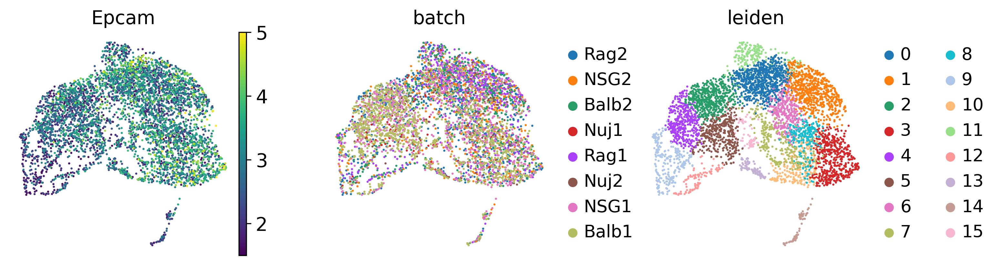

In [33]:
sc.pl.embedding(Epcam_p, basis='umap',
                color=[
                    'Epcam', # —> epithelial cells
#                     'Pecam1',# —> Endothelial cells
#                     'Fbln1', # —> fibroblasts
                    'batch',
                    'leiden'
                ],
                size=10,
                vmin=1.5,vmax=5,
                save='_Epcam_p_harmony.pdf')

## _T Cells_

In [11]:
mergedadata

AnnData object with n_obs × n_vars = 27675 × 32285
    obs: 'CD45_protein', 'CD3_protein', 'CD8a_protein', 'CD4_protein', 'CD14_protein', 'CD19_protein', 'CD11c_protein', 'PDL1_protein', 'TIM3_protein', 'CTLA4_protein', 'batch', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

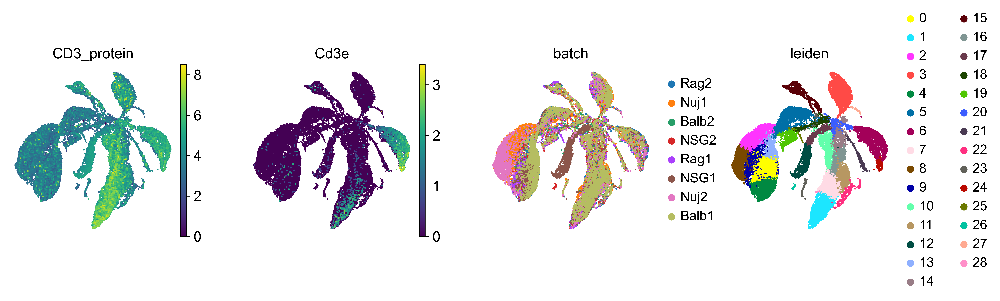

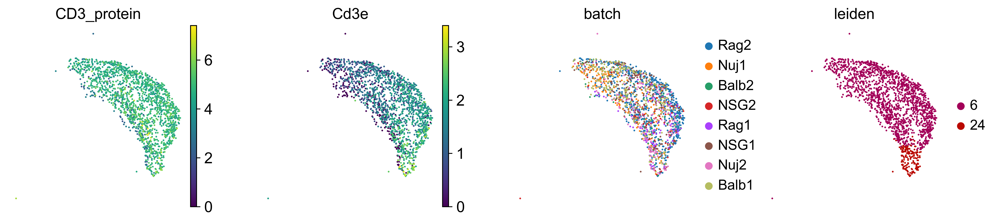

In [28]:
sc.pl.embedding(
    mergedadata, basis='umap', color=['CD3_protein', 'Cd3e','batch','leiden'], size=10,
    # save='_T_cells.pdf'
)

sc.pl.embedding(
    mergedadata[[clst in ['6','24'] for clst in mergedadata.obs.leiden]], 
    basis='umap',
    color=[
        'CD3_protein', 'Cd3e',
        # 'CD8a_protein', 'Cd8a',
        # 'CD4_protein', 'Cd4',
        # 'CD14_protein', 'Cd14',
        # 'CD19_protein', 'Cd19','Ms4a1',
        # 'CD11c_protein', 'Itgax',
        'batch',
        'leiden'
    ],
    size=10,
#     vmin=0,
#     vmax=3,
    # save='_T_cells.pdf'
)


In [29]:
T_cells = mergedadata[[clst in ['6','24'] for clst in mergedadata.obs.leiden]].copy()

In [30]:
T_cells.write('preprocessing/T_cells.h5ad.gz',compression='gzip')

## _Non-immune_

In [65]:
NonImmuneadata = mergedadata[mergedadata.obs.CD45_protein <= 6].copy()

In [66]:
# clustering(NonImmuneadata)

In [67]:
sc.pl.embedding(NonImmuneadata, basis='umap',
                color=[
                    'Epcam', # —> epithelial cells
                    'Pecam1',# —> Endothelial cells
                    'Fbln1', # —> fibroblasts
                    'batch',
                    'leiden'
                ],
                size=10,
#                 vmin=2,vmax=5,
                save='_NonImmune.pdf')

In [68]:
CD45adata = mergedadata[mergedadata.obs.CD45_protein > 6].copy()

In [69]:
# clustering(CD45adata)

In [70]:
sc.pl.embedding(
    CD45adata, basis='umap',
    color=[
        'Epcam', # —> epithelial cells
        'Pecam1',# —> Endothelial cells
        'Fbln1', # —> fibroblasts
                    
        'CD3_protein', 'Cd3e',
        'CD8a_protein', 'Cd8a',
        'CD4_protein', 'Cd4',
        'CD14_protein', 'Cd14',
        'CD19_protein', 'Cd19','Ms4a1',
        'CD11c_protein', 'Itgax',

        'batch',
        'leiden'
    ],
#                 size=2,vmin=3,
#                 vmax=5
    save='_CD45+.pdf'
)

In [ ]:
# clustering(mergedadata,lognorm=False,n_neighbor=10,res=1)

## 4 conditions 

In [46]:
Balb = mergedadata[[cell in ['Balb1', 'Balb2'] for cell in mergedadata.obs.batch]].copy()
NSG = mergedadata[[cell in ['NSG1', 'NSG2'] for cell in mergedadata.obs.batch]].copy()
Nuj = mergedadata[[cell in ['Nuj1', 'Nuj2'] for cell in mergedadata.obs.batch]].copy()
Rag = mergedadata[[cell in ['Rag1', 'Rag2'] for cell in mergedadata.obs.batch]].copy()

In [48]:
clustering(Balb)

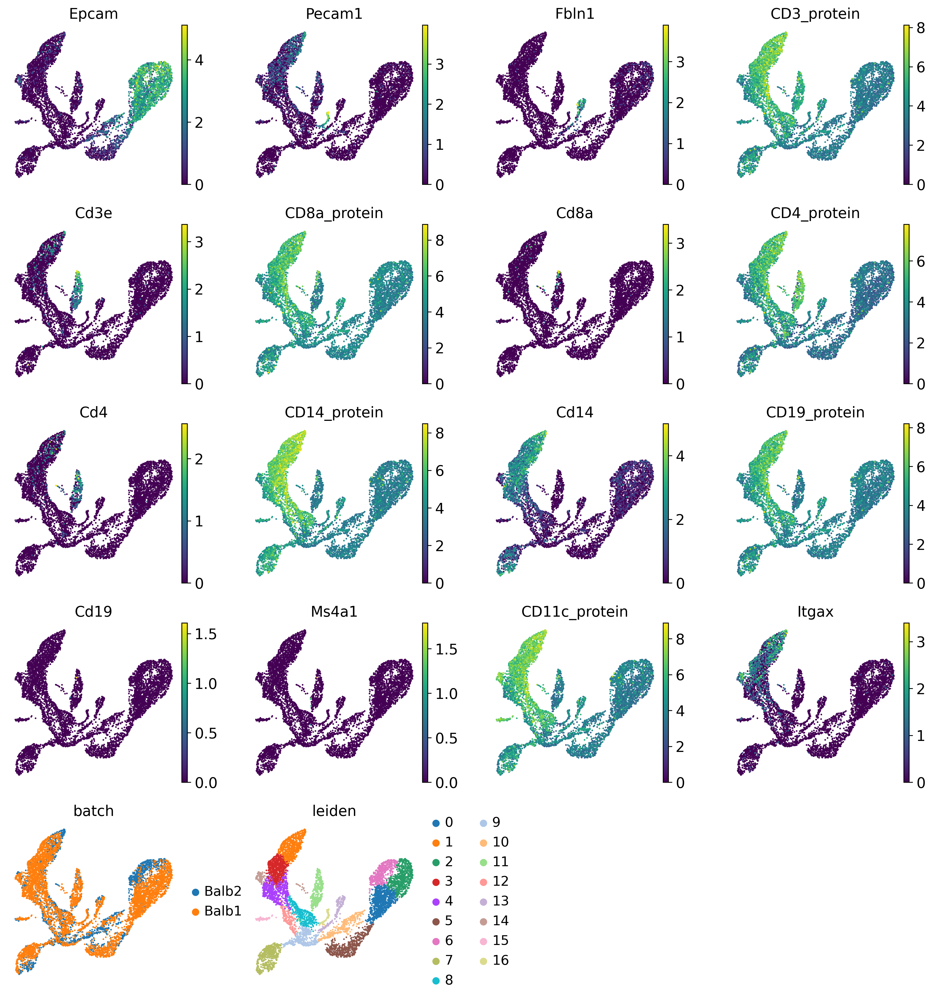

In [49]:
sc.pl.embedding(
    Balb, basis='umap',
    color=[
        'Epcam', # —> epithelial cells
        'Pecam1',# —> Endothelial cells
        'Fbln1', # —> fibroblasts
                    
        'CD3_protein', 'Cd3e',
        'CD8a_protein', 'Cd8a',
        'CD4_protein', 'Cd4',
        'CD14_protein', 'Cd14',
        'CD19_protein', 'Cd19','Ms4a1',
        'CD11c_protein', 'Itgax',

        'batch',
        'leiden'
    ],
    size=10,
#     vmin=0,
#     vmax=3,
    save='_Balb.pdf'
)

In [44]:
len([i for i in mergedadata.obs.CD45_protein > 6 if i == True])

11957

In [45]:
len([i for i in mergedadata.obs.CD45_protein > 6 if i != True])

15718

In [55]:
sc.pl.embedding(
    mergedadata, basis='umap',
    color=[
        'Epcam', # —> epithelial cells
        'Pecam1',# —> Endothelial cells
        'Fbln1', # —> fibroblasts
                    
        'CD3_protein', 'Cd3e',
        'CD8a_protein', 'Cd8a',
        'CD4_protein', 'Cd4',
        'CD14_protein', 'Cd14',
        'CD19_protein', 'Cd19','Ms4a1',
        'CD11c_protein', 'Itgax',

        'batch',
        'leiden'
    ],
    size=10,
#     vmin=0,
#     vmax=3,
    save='_cell_typing.pdf'
)

In [71]:
# sc.pl.embedding(mergedadata, basis='umap',color=mergedadata.obs.columns, size=2,vmin=2,vmax=8)#,save='_harmony.pdf')

In [72]:
# %%time 
# pdf_pages = PdfPages('figures/umap.pdf')

# # The PDF document
# for sample in data:
#     adata = data[sample].copy()

#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(dpi=300)

#     # Plot whatever you wish to plot
#     print ('\033[1m' + sample)
#     fig = sc.pl.embedding(adata, basis='rna_umap',color=adata.obs.columns[2:], size=10,show=False,return_fig=True)
#     fig.suptitle(sample +'\n'+str(adata.shape[0])+' cells, '+str(adata.shape[1])+' genes', fontsize=20)
    
#     fig.set_size_inches(18.5, 10.5) # https://stackoverflow.com/questions/332289/how-do-you-change-the-size-of-figures-drawn-with-matplotlib
    
#     # Done with the page
#     pdf_pages.savefig(fig)
#     plt.close(fig)    
# #     del adata
    
# # Write the PDF document to the disk
# pdf_pages.close()

## 4. Huge heatmap!

In [38]:
# clustering(mergedadata,lognorm=False,n_neighbor=10,res=1)

In [64]:
mergedadata.obs.columns#[:-2]

Index(['CD45_protein', 'CD3_protein', 'CD8a_protein', 'CD4_protein',
       'CD14_protein', 'CD19_protein', 'CD11c_protein', 'PDL1_protein',
       'TIM3_protein', 'CTLA4_protein', 'batch', 'leiden'],
      dtype='object')

In [69]:
sc.pl.heatmap(mergedadata, mergedadata.obs.columns[:-2], groupby='leiden', dendrogram=True,save='.pdf',figsize=(5,30),show=False)

{'heatmap_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff202ac3b38>,
 'groupby_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff1e005fb70>,
 'dendrogram_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff201d25c88>}

In [ ]:
# # The PDF document
pdf_pages = PdfPages('figures/violin_cite.pdf')

for cite in mergedadata.obs.columns[:-2]:
    # Create a figure instance (ie. a new page)
    fig = plot.figure(figsize=(12, 6), dpi=100)

    # Plot whatever you wish to plot
    print ('\033[1m' + cite)
    ax = plt.subplot()
    sc.pl.violin(mergedadata, cite, groupby='leiden',stripplot=False,ax=ax,rotation=90,show=False)
    # Done with the page
    pdf_pages.savefig(fig)
    
# Write the PDF document to the disk
pdf_pages.close()

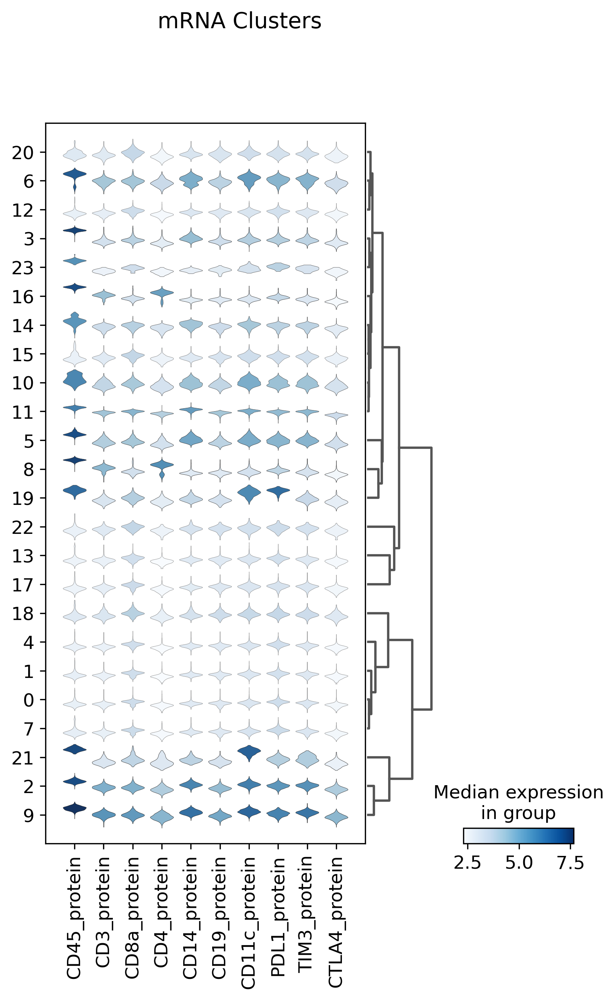

In [72]:
sc.pl.stacked_violin(
    mergedadata,
    mergedadata.obs.columns[:-2],
    groupby='leiden',
    title='mRNA Clusters',
    save='mRNA.pdf',
    dendrogram=True
)

In [73]:
# find gene markers in the 'dataset' group.
sc.tl.rank_genes_groups(mergedadata, 'leiden', method='wilcoxon', n_genes=25)

In [74]:
sc.pl.rank_genes_groups_heatmap(mergedadata, n_genes=3, use_raw=False, vmin=-3, vmax=3, show_gene_labels=True,cmap='bwr',save='_rank_genes_groups_leiden.pdf',figsize=(30,60),show=False)

{'heatmap_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff202dd8c88>,
 'groupby_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff20044a9b0>,
 'dendrogram_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff20055c860>,
 'gene_groups_ax': <matplotlib.axes._subplots.AxesSubplot at 0x7ff203831c88>}

In [10]:
mergedadata.write('preprocessing/mergedadata.h5ad.gz',compression='gzip')

In [88]:
!conda env export --from-history

name: sc-analysis
channels:
  - anaconda
  - r
  - conda-forge
  - bioconda
dependencies:
  - scanpy
  - scvi-tools
  - scrublet
  - leidenalg
  - cellrank
prefix: /data_gilbert/home/aarab/anaconda3/envs/sc-analysis


In [51]:
# import altair as alt
# from functools import partial

# alt.renderers.enable("png")
# alt.data_transformers.disable_max_rows()

# def embedding_chart(df: pd.DataFrame, coord_pat: str, *, size=5) -> alt.Chart:
#     """Make schema for coordinates, like sc.pl.embedding."""
#     x, y = df.columns[df.columns.str.contains(coord_pat)]
#     return (
#         alt.Chart(plotdf, height=300, width=300)
#         .mark_circle(size=size)
#         .encode(
#             x=alt.X(x, axis=None),
#             y=alt.Y(y, axis=None),
#         )
#     )

# def umap_chart(df: pd.DataFrame, **kwargs) -> alt.Chart:
#     """Like sc.pl.umap, but just the coordinates."""
#     return embedding_chart(df, "umap", **kwargs)

# def encode_color(c: alt.Chart, col: str, *, qdomain=(0, 1), scheme: str = "lightgreyred") -> alt.Chart:
#     """Add colors to an embedding plot schema."""
#     base = c.properties(title=col)
#     if pd.api.types.is_categorical(c.data[col]):
#         return base.encode(color=col)
#     else:
#         return base.encode(
#             color=alt.Color(
#                 col,
#                 scale=alt.Scale(
#                     scheme=scheme,
#                     clamp=True,
#                     domain=list(c.data[col].quantile(qdomain)),
#                     nice=True,
#                 )
#             )
#         )
#     plotdf = sc.get.obs_df(
#         rna,
#         obsm_keys=[("X_umap", i) for i in range(2)] + [("protein", i) for i in rna.obsm["protein"].columns]
#     )

#     fig = (
#         alt.concat(
#             *map(partial(encode_color, umap_chart(plotdf), qdomain=(0, .95)), plotdf.columns[3:]),
#             columns=2
#         )
#         .resolve_scale(color='independent')
#         .configure_axis(grid=True)
#     )

In [52]:
# def preprocessing(adata):
#     # Basic filtering:
#     sc.pp.filter_genes(adata, min_cells=10)
#     sc.pp.filter_cells(adata, min_genes=150)
#     # annotate the group of mitochondrial genes as 'mt'
#     adata.var['mt'] = adata.var.index.str.startswith('MT-')  
#     # Remove cells that have too many mitochondrial genes expressed or too many total counts:
#     sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
#     adata = adata[adata.obs.n_genes_by_counts < 2500, :]
#     adata = adata[adata.obs.pct_counts_mt < 5, :]
#     # Total-count normalize (library-size correct) the data matrix 
#     # 𝐗 to 10,000 reads per cell, so that counts become comparable among cells.
#     sc.pp.normalize_per_cell(adata)
#     # Logarithmize the data:
#     sc.pp.log1p(adata)
#     # Identify highly-variable genes.
#     sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     adata.raw = adata
#     # Actually do the filtering
#     adata = adata[:, adata.var.highly_variable]
#     # Regress out effects of total counts per cell and the percentage of mitochondrial genes expressed. 
#     # Scale the data to unit variance.
#     sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt'])
#     # Scale each gene to unit variance. Clip values exceeding standard deviation 10.
#     sc.pp.scale(adata, max_value=10)